In [2]:
import os
import zipfile
import tarfile
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (
    Input, Dense, Conv2D, Conv2DTranspose, Flatten,
    Reshape, Dropout, LeakyReLU
)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: []


In [3]:
# Change this to the folder containing your Anime Face images.
# Colab example: DATA_DIR = "/content/anime_data"
# Windows Jupyter example: DATA_DIR = r"D:\datasets\anime_data"
DATA_DIR = "/content/anime_data"

# Optional: path to the original archive, if you have a valid ZIP or TAR file.
# Leave as None if the dataset is already extracted into DATA_DIR.
ARCHIVE_PATH = None
# Example: ARCHIVE_PATH = "/content/anime_faces.zip"

IMAGE_SIZE = 32
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("DATA_DIR:", DATA_DIR)
print("Folder exists:", os.path.isdir(DATA_DIR))

DATA_DIR: /content/anime_data
Folder exists: False


In [4]:
# Run this cell only if you have an archive file and want to extract it.
# Set ARCHIVE_PATH above to the exact path of that file first.

if ARCHIVE_PATH is not None:
    if not os.path.isfile(ARCHIVE_PATH):
        raise FileNotFoundError(f"Archive not found: {ARCHIVE_PATH}")

    os.makedirs(DATA_DIR, exist_ok=True)

    if zipfile.is_zipfile(ARCHIVE_PATH):
        with zipfile.ZipFile(ARCHIVE_PATH, "r") as zf:
            zf.extractall(DATA_DIR)
        print("ZIP extracted to:", DATA_DIR)
    elif tarfile.is_tarfile(ARCHIVE_PATH):
        with tarfile.open(ARCHIVE_PATH, "r:*") as tf_archive:
            tf_archive.extractall(DATA_DIR)
        print("TAR archive extracted to:", DATA_DIR)
    else:
        with open(ARCHIVE_PATH, "rb") as f:
            signature = f.read(16)
        raise ValueError(
            "This file is not recognized as a ZIP/TAR archive. "
            f"First bytes: {signature!r}. Download the original dataset archive "
            "or extract it manually, then set DATA_DIR to the image folder."
        )
else:
    print("Skipping archive extraction; using DATA_DIR.")

Skipping archive extraction; using DATA_DIR.


In [6]:
import os

print("Current working directory:", os.getcwd())
print("\nFiles and folders:")

for item in os.listdir():
    print(item)

Current working directory: C:\Users\nc307

Files and folders:
# K-NEAREST NEIGHBORS - WITH LIBRARY.ipynb
-1.14-windows.xml
.anaconda
.arduinoIDE
.bash_history
.cache
.cargo
.claude
.claude.json
.conda
.config
.continuum
.copilot
.cursor
.dbclient
.eclipse
.gemini
.gitconfig
.ipynb_checkpoints
.ipython
.jupyter
.keras
.labelImgSettings.pkl
.lemminx
.lesshst
.local
.m2
.matplotlib
.ms-ad
.node_repl_history
.p2
.packettracer
.python_history
.rustup
.streamlit
.viminfo
.VirtualBox
.virtual_documents
.vscode
.vscode-shared
11-bansude(SB).ipynb
16_air_quality_prediction.csv
2SB.ipynb
92.jpg
abc.c++
abc.exe
advertising (1).csv
Advertising.csv
AdvertisingML.ipynb
AM py
Aniket_korde_gen_Ai_assi.ipynb
ansel
AppData
Application Data
archive (15).zip
archive.zip
Au.ipynbtomated EDA Using
check.py
Cisco Packet Tracer 8.2.2
Cisco Packet Tracer 9.0.0
classification_regression.ipynb
Clustering.ipynb
CN Tut 09.ipynb
cnn_accuracy.png
cnn_loss.png
cnn_vs_transfer.png
Contacts
Cookies
creditcard.ipynb
Cro

In [7]:
from pathlib import Path

# Change this to your actual dataset folder
DATA_DIR = r"D:\datasets\anime_data"

IMAGE_SIZE = 32
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("Folder exists:", Path(DATA_DIR).exists())

Folder exists: False


In [9]:
from pathlib import Path

downloads = Path.home() / "Downloads"

print("Downloads folder:", downloads)
print("Files found:")

for file in downloads.iterdir():
    print(file.name, "-", round(file.stat().st_size / (1024 * 1024), 2), "MB")

Downloads folder: C:\Users\nc307\Downloads
Files found:
(4) Instagram.html - 1.25 MB
(4) Instagram_files - 0.0 MB
.java - 0.0 MB
01_data_cleaning_analysis.ipynb - 0.11 MB
02_logistic_regression.ipynb - 0.03 MB
03_decision_tree.ipynb - 0.08 MB
05_xgboost.ipynb - 0.07 MB
08_naive_bayes.ipynb - 0.07 MB
09_adaboost.ipynb - 0.1 MB
1...pdf - 0.36 MB
1.jpeg - 0.13 MB
106105167.pdf - 44.27 MB
11.jpeg - 0.1 MB
123.png - 0.01 MB
15_4_house_price_prediction.ipynb - 0.73 MB
16_air_quality_prediction.csv - 0.06 MB
2.jpeg - 0.13 MB
202401090075.pdf - 0.84 MB
202401110017 EI(Pract-1).docx - 0.98 MB
202401110017 IA activity ppt presentation .pdf - 1.9 MB
202401110017@mitaoe.ac.in_5323540_s5323540_5553128_Aug_16_2026_9-02-36pm_PDT - 0.0 MB
202401110017_DBMS_nosql_Assignment.docx - 1.22 MB
202401110017_EI.docx - 0.17 MB
202401110017_Nilesh_Chavan.pdf - 0.21 MB
202401110017_Practice_Lab_Assignment_1 (1).pdf - 0.26 MB
202401110030.pdf - 1.52 MB
202401110033 Practical No-03.pdf - 0.4 MB
202401110033_AI_Eve

In [10]:
import zipfile
from pathlib import Path

ZIP_PATH = Path.home() / "Downloads" / "archive (15).zip"

print("File exists:", ZIP_PATH.exists())

if ZIP_PATH.exists():
    print("File size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")
    print("Valid ZIP:", zipfile.is_zipfile(ZIP_PATH))

File exists: True
File size: 394.66 MB
Valid ZIP: True


In [11]:
from pathlib import Path
import zipfile

DATA_DIR = Path(r"D:\datasets\anime_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted to:", DATA_DIR)

Dataset extracted to: D:\datasets\anime_data


In [12]:
data_root = Path(DATA_DIR)

if not data_root.exists():
    raise FileNotFoundError(
        f"Dataset folder does not exist: {DATA_DIR}. "
        "Create/extract the folder and update DATA_DIR in Cell 2."
    )

all_files = [p for p in data_root.rglob("*") if p.is_file()]
image_paths = [
    str(p) for p in all_files
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Files in dataset folder:", len(all_files))
print("Images found:", len(image_paths))
print("File extensions:", sorted({p.suffix.lower() for p in all_files})[:30])
print("First 10 files:")
for p in all_files[:10]:
    print(p)

if not image_paths:
    raise ValueError(
        "No image files were found. Check the printed file list/extensions. "
        "DATA_DIR must point to the folder containing .jpg, .jpeg, .png, .webp, or .bmp images. "
        "If the folder is empty or contains another archive, extract/download the actual dataset first."
    )

Files in dataset folder: 63565
Images found: 63565
File extensions: ['.jpg']
First 10 files:
D:\datasets\anime_data\images\0_2000.jpg
D:\datasets\anime_data\images\10000_2004.jpg
D:\datasets\anime_data\images\10001_2004.jpg
D:\datasets\anime_data\images\10002_2004.jpg
D:\datasets\anime_data\images\10003_2004.jpg
D:\datasets\anime_data\images\10004_2004.jpg
D:\datasets\anime_data\images\10005_2004.jpg
D:\datasets\anime_data\images\10006_2004.jpg
D:\datasets\anime_data\images\10007_2004.jpg
D:\datasets\anime_data\images\10008_2004.jpg


In [14]:
def load_real_samples(paths, image_size=IMAGE_SIZE, max_images=None):
    if max_images is not None:
        paths = paths[:max_images]

    images = []
    skipped = 0

    for path in paths:
        try:
            with Image.open(path) as img:
                img = img.convert("RGB")
                img = img.resize((image_size, image_size))
                images.append(np.asarray(img, dtype=np.float32))
        except Exception as exc:
            skipped += 1

    if len(images) == 0:
        raise ValueError(
            "Image paths were found, but none could be opened. "
            "They may be corrupt or may not be real image files."
        )

    X = np.asarray(images, dtype=np.float32)
    X = (X - 127.5) / 127.5  # Scale pixels from [0,255] to [-1,1]
    print("Images loaded:", len(X), "| Files skipped:", skipped)
    print("Dataset shape:", X.shape)
    return X

# Use max_images=5000 to test faster, or None to load every image.
dataset = load_real_samples(image_paths, max_images=None)

Images loaded: 63565 | Files skipped: 0
Dataset shape: (63565, 32, 32, 3)


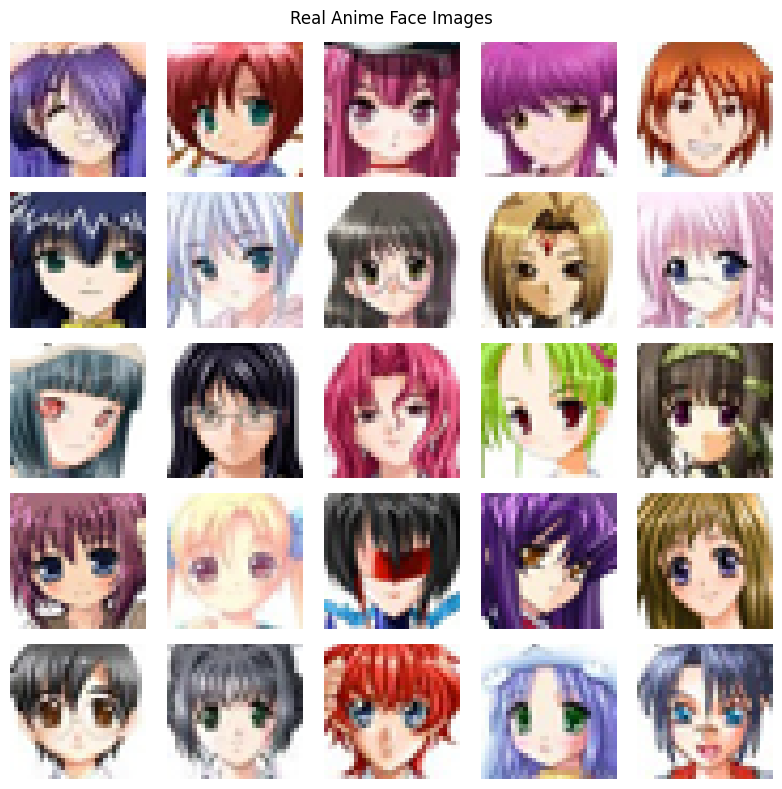

In [15]:
n_show = min(25, len(dataset))
plt.figure(figsize=(8, 8))

for i in range(n_show):
    plt.subplot(5, 5, i + 1)
    plt.axis("off")
    plt.imshow(np.clip((dataset[i] + 1) / 2, 0, 1))

plt.suptitle("Real Anime Face Images")
plt.tight_layout()
plt.show()

In [16]:
def define_discriminator(in_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)):
    model = Sequential(name="discriminator")
    model.add(Input(shape=in_shape))

    model.add(Conv2D(64, (3, 3), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    model.add(Conv2D(128, (3, 3), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    model.add(Conv2D(256, (3, 3), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    model.add(Flatten())
    model.add(Dropout(0.4))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        loss="binary_crossentropy",
        optimizer=Adam(learning_rate=0.0002, beta_1=0.5),
        metrics=["accuracy"]
    )
    return model

d_model = define_discriminator()
d_model.summary()

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)               │ (None, 32, 32, 64)    │        1,792 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu (LeakyReLU)       │ (None, 32, 32, 64)    │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_1 (Conv2D)             │ (None, 16, 16, 128)   │       73,856 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_1 (LeakyReLU)     │ (None, 16, 16, 128)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_2 (Conv2D)             │ (None, 8, 8, 128)     │      147,584 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_2 (LeakyReLU)     │ (None, 8, 8, 128)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_3 (Conv2D)             │ (None, 4, 4, 256)     │      295,168 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_3 (LeakyReLU)     │ (None, 4, 4, 256)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ flatten (Flatten)             │ (None, 4096)          │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dropout (Dropout)             │ (None, 4096)          │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ dense (Dense)                 │ (None, 1)             │        4,097 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 522,497 (1.99 MB)

 Trainable params: 522,497 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
def generate_real_samples(dataset, n_samples):
    ix = np.random.randint(0, dataset.shape[0], n_samples)
    X = dataset[ix]
    y = np.ones((n_samples, 1), dtype=np.float32)
    return X, y

def generate_latent_points(latent_dim, n_samples):
    points = np.random.randn(latent_dim * n_samples).astype(np.float32)
    return points.reshape(n_samples, latent_dim)

def generate_fake_samples(g_model, latent_dim, n_samples):
    x_input = generate_latent_points(latent_dim, n_samples)
    X = g_model.predict(x_input, verbose=0)
    y = np.zeros((n_samples, 1), dtype=np.float32)
    return X, y

In [18]:
def define_generator(latent_dim):
    model = Sequential(name="generator")
    model.add(Input(shape=(latent_dim,)))

    # Create 4x4 feature maps
    model.add(Dense(256 * 4 * 4))
    model.add(LeakyReLU(negative_slope=0.2))
    model.add(Reshape((4, 4, 256)))

    # 4x4 -> 8x8
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    # 8x8 -> 16x16
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    # 16x16 -> 32x32
    model.add(Conv2DTranspose(128, (4, 4), strides=(2, 2), padding="same"))
    model.add(LeakyReLU(negative_slope=0.2))

    model.add(Conv2D(3, (3, 3), activation="tanh", padding="same"))
    return model

latent_dim = 100
g_model = define_generator(latent_dim)
g_model.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape          ┃      Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ dense_1 (Dense)               │ (None, 4096)          │      413,696 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_4 (LeakyReLU)     │ (None, 4096)          │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ reshape (Reshape)             │ (None, 4, 4, 256)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_transpose              │ (None, 8, 8, 128)     │      524,416 │
│ (Conv2DTranspose)             │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_5 (LeakyReLU)     │ (None, 8, 8, 128)     │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_transpose_1            │ (None, 16, 16, 128)   │      262,272 │
│ (Conv2DTranspose)             │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_6 (LeakyReLU)     │ (None, 16, 16, 128)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_transpose_2            │ (None, 32, 32, 128)   │      262,272 │
│ (Conv2DTranspose)             │                       │              │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ leaky_re_lu_7 (LeakyReLU)     │ (None, 32, 32, 128)   │            0 │
├───────────────────────────────┼───────────────────────┼──────────────┤
│ conv2d_4 (Conv2D)             │ (None, 32, 32, 3)     │        3,459 │
└───────────────────────────────┴───────────────────────┴──────────────┘

 Total params: 1,466,115 (5.59 MB)

 Trainable params: 1,466,115 (5.59 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
def define_gan(g_model, d_model):
    d_model.trainable = False
    model = Sequential([g_model, d_model], name="combined_gan")
    model.compile(
        loss="binary_crossentropy",
        optimizer=Adam(learning_rate=0.0002, beta_1=0.5)
    )
    return model

gan_model = define_gan(g_model, d_model)

In [20]:
OUTPUT_DIR = "anime_gan_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_plot(examples, epoch, n=5):
    examples = np.clip((examples + 1) / 2, 0, 1)
    count = min(n * n, len(examples))

    plt.figure(figsize=(7, 7))
    for i in range(count):
        plt.subplot(n, n, i + 1)
        plt.axis("off")
        plt.imshow(examples[i])

    plt.tight_layout()
    filename = os.path.join(OUTPUT_DIR, f"generated_epoch_{epoch + 1:03d}.png")
    plt.savefig(filename)
    plt.show()
    plt.close()
    print("Saved:", filename)

def summarize_performance(epoch, g_model, d_model, dataset, latent_dim):
    n_samples = min(25, len(dataset))
    X_real, y_real = generate_real_samples(dataset, n_samples)
    _, acc_real = d_model.evaluate(X_real, y_real, verbose=0)

    X_fake, y_fake = generate_fake_samples(g_model, latent_dim, n_samples)
    _, acc_fake = d_model.evaluate(X_fake, y_fake, verbose=0)

    print(f"Discriminator accuracy: real={acc_real*100:.1f}%, fake={acc_fake*100:.1f}%")
    save_plot(X_fake, epoch, n=5)
    g_model.save(os.path.join(OUTPUT_DIR, f"generator_epoch_{epoch + 1:03d}.keras"))

In [21]:
def train(g_model, d_model, gan_model, dataset, latent_dim, n_epochs=20, n_batch=64):
    if len(dataset) < 2:
        raise ValueError("At least two images are required.")

    half_batch = max(1, n_batch // 2)
    batches_per_epoch = max(1, len(dataset) // n_batch)

    for epoch in range(n_epochs):
        d_real_losses = []
        d_fake_losses = []
        g_losses = []

        for _ in range(batches_per_epoch):
            # Train discriminator on real images
            X_real, y_real = generate_real_samples(dataset, half_batch)
            d_loss1, _ = d_model.train_on_batch(X_real, y_real)

            # Train discriminator on generated images
            X_fake, y_fake = generate_fake_samples(g_model, latent_dim, half_batch)
            d_loss2, _ = d_model.train_on_batch(X_fake, y_fake)

            # Train generator through the combined GAN
            X_gan = generate_latent_points(latent_dim, n_batch)
            y_gan = np.ones((n_batch, 1), dtype=np.float32)
            g_loss = gan_model.train_on_batch(X_gan, y_gan)

            d_real_losses.append(float(d_loss1))
            d_fake_losses.append(float(d_loss2))
            g_losses.append(float(g_loss))

        print(
            f"Epoch {epoch + 1}/{n_epochs} | "
            f"D(real)={np.mean(d_real_losses):.4f} | "
            f"D(fake)={np.mean(d_fake_losses):.4f} | "
            f"G={np.mean(g_losses):.4f}"
        )

        if (epoch + 1) % 5 == 0 or epoch == n_epochs - 1:
            summarize_performance(epoch, g_model, d_model, dataset, latent_dim)

    return g_model, d_model, gan_model

C:\Users\nc307\AppData\Roaming\Python\Python313\site-packages\keras\src\backend\tensorflow\trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 1/20 | D(real)=0.9730 | D(fake)=0.9737 | G=0.3597
Epoch 2/20 | D(real)=1.0573 | D(fake)=1.0574 | G=0.2867
Epoch 3/20 | D(real)=1.0811 | D(fake)=1.0812 | G=0.2705
Epoch 4/20 | D(real)=1.1006 | D(fake)=1.1007 | G=0.2586
Epoch 5/20 | D(real)=1.1196 | D(fake)=1.1197 | G=0.2480
Discriminator accuracy: real=20.0%, fake=0.0%


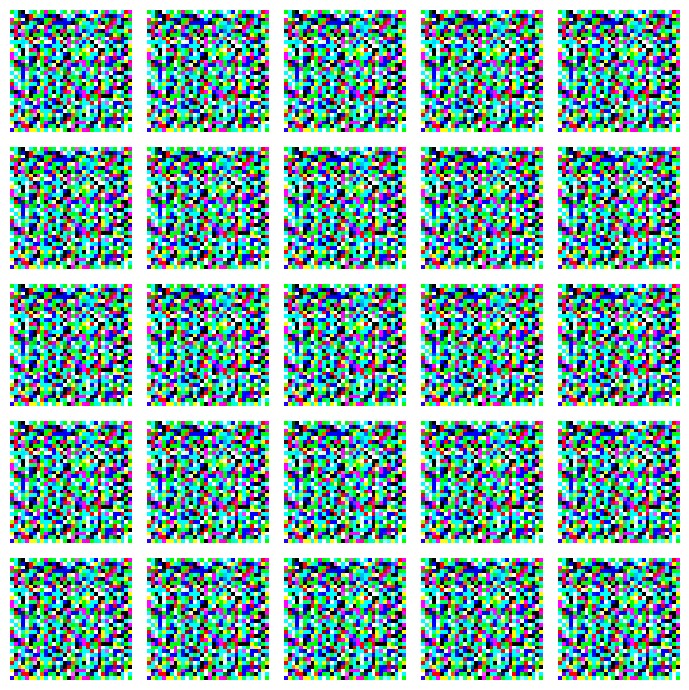

Saved: anime_gan_results\generated_epoch_005.png
Epoch 6/20 | D(real)=1.2308 | D(fake)=1.2326 | G=0.2384
Epoch 7/20 | D(real)=1.2449 | D(fake)=1.2451 | G=0.2298
Epoch 8/20 | D(real)=1.2583 | D(fake)=1.2584 | G=0.2221
Epoch 9/20 | D(real)=1.2715 | D(fake)=1.2716 | G=0.2151
Epoch 10/20 | D(real)=1.2834 | D(fake)=1.2835 | G=0.2088
Discriminator accuracy: real=4.0%, fake=0.0%


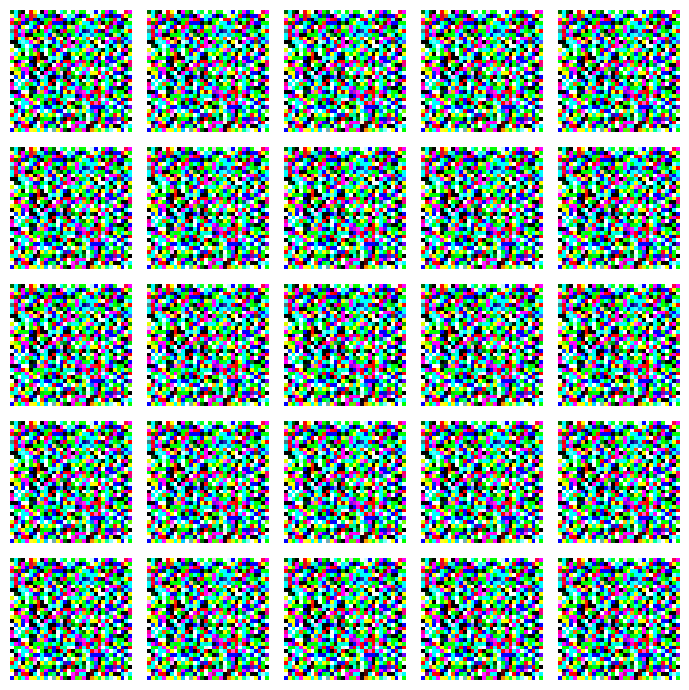

Saved: anime_gan_results\generated_epoch_010.png
Epoch 11/20 | D(real)=1.3467 | D(fake)=1.3490 | G=0.2032
Epoch 12/20 | D(real)=1.3564 | D(fake)=1.3567 | G=0.1980
Epoch 13/20 | D(real)=1.3637 | D(fake)=1.3638 | G=0.1934
Epoch 14/20 | D(real)=1.3694 | D(fake)=1.3695 | G=0.1892
Epoch 15/20 | D(real)=1.3745 | D(fake)=1.3746 | G=0.1855
Discriminator accuracy: real=0.0%, fake=0.0%


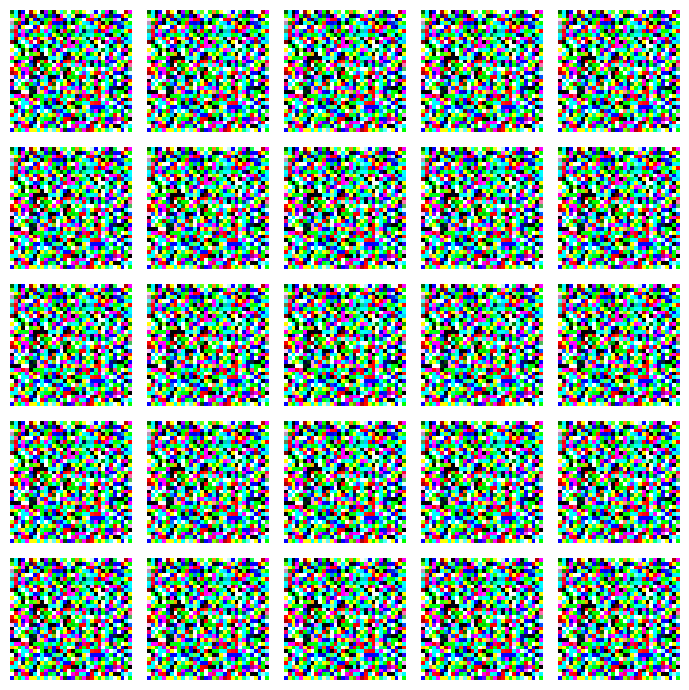

Saved: anime_gan_results\generated_epoch_015.png
Epoch 16/20 | D(real)=1.4047 | D(fake)=1.4071 | G=0.1820
Epoch 17/20 | D(real)=1.4115 | D(fake)=1.4118 | G=0.1787
Epoch 18/20 | D(real)=1.4153 | D(fake)=1.4154 | G=0.1758
Epoch 19/20 | D(real)=1.4181 | D(fake)=1.4182 | G=0.1730
Epoch 20/20 | D(real)=1.4208 | D(fake)=1.4208 | G=0.1705
Discriminator accuracy: real=0.0%, fake=0.0%


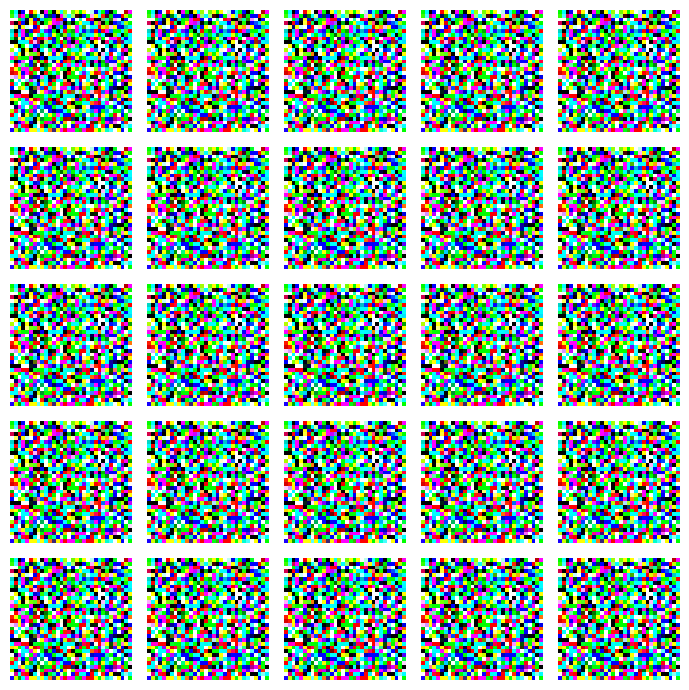

Saved: anime_gan_results\generated_epoch_020.png


In [22]:
# Start with 20 epochs. Use n_batch=16 if your system runs out of memory.
EPOCHS = 20
BATCH_SIZE = 64

g_model, d_model, gan_model = train(
    g_model, d_model, gan_model,
    dataset, latent_dim,
    n_epochs=EPOCHS,
    n_batch=BATCH_SIZE
)

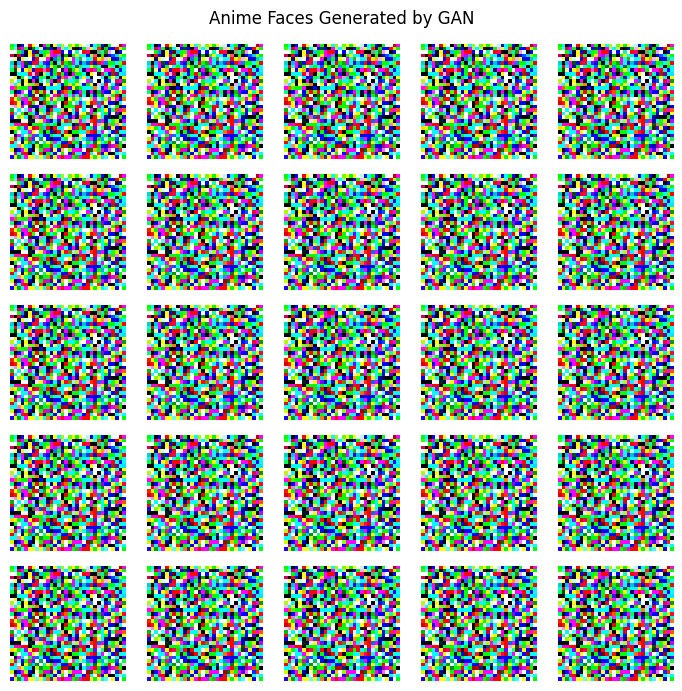

In [ ]:
X_generated, _ = generate_fake_samples(g_model, latent_dim, 25)
X_display = np.clip((X_generated + 1) / 2, 0, 1)

plt.figure(figsize=(7, 7))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.axis("off")
    plt.imshow(X_display[i])

plt.suptitle("Anime Faces Generated by GAN")
plt.tight_layout()
plt.show()

In [ ]:
g_model.save("anime_generator.keras")
d_model.save("anime_discriminator.keras")
print("Saved anime_generator.keras and anime_discriminator.keras")

Saved anime_generator.keras and anime_discriminator.keras


Images found: 63565


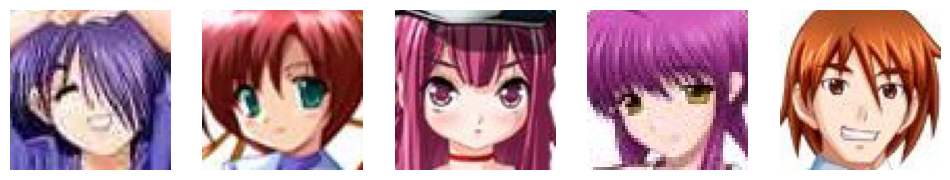

In [25]:
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATA_DIR = Path(r"D:\datasets\anime_data")

images = list(DATA_DIR.rglob("*.jpg"))[:5]

print("Images found:", len(list(DATA_DIR.rglob("*.jpg"))))

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for ax, path in zip(axes, images):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.axis("off")

plt.show()

Total images found: 63565


Dataset ready!


ValueError: in user code:

    File "C:\Users\nc307\AppData\Local\Temp\ipykernel_20292\501394885.py", line 12, in train_step  *
        fake_output = discriminator(fake_images, training=True)
    File "C:\Users\nc307\AppData\Roaming\Python\Python313\site-packages\keras\src\utils\traceback_utils.py", line 122, in error_handler  **
        raise e.with_traceback(filtered_tb) from None
    File "C:\Users\nc307\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\input_spec.py", line 228, in assert_input_compatibility
        raise ValueError(

    ValueError: Exception encountered when calling Sequential.call().
    
    [1mInput 0 with name 'None' of layer 'dense_5' is incompatible with the layer: expected axis -1 of input shape to have value 16384, but received input with shape (64, 4096)[0m
    
    Arguments received by Sequential.call():
      • inputs=tf.Tensor(shape=(64, 32, 32, 3), dtype=float32)
      • training=True
      • mask=None
      • kwargs=<class 'inspect._